# Multi-robot area coverage simulation

Reproduces the results in the article *"Collective Intelligence: How Multiple AI Agents Coordinate Physical Robots"*.

Four coordination strategies are compared on a 40 x 40 grid:

| Strategy | Description | Type |
|---|---|---|
| `random` | random walk, no memory, no messages | swarm rule |
| `repulse` | random walk biased away from nearby teammates | swarm rule |
| `frontier_local` | go to nearest unseen cell, swap maps with robots in radio range | distributed |
| `frontier_shared` | go to nearest unseen cell, one global map on a central server | centralized |



In [2]:
import json

import numpy as np
import matplotlib.pyplot as plt

## Parameters

In [3]:
GRID = 40            # arena is GRID x GRID cells
SENSE = 2            # robot senses a (2*SENSE+1)^2 = 5x5 patch
MAX_STEPS = 1500     # runs that have not reached the target are stopped here
TARGET = 0.95        # coverage goal (95% of cells seen)
CLAIM_PENALTY = 12.0 # extra cost for cells near a teammate's goal
CLAIM_RADIUS = 8     # "near" = Manhattan distance below this
MOVES = np.array([(1, 0), (-1, 0), (0, 1), (0, -1)])

## Helper functions

In [4]:
def sense(seen, pos):
    """Mark the 5x5 patch around pos as seen."""
    x, y = pos
    seen[max(0, x - SENSE):x + SENSE + 1, max(0, y - SENSE):y + SENSE + 1] = True


def step_toward(pos, goal):
    """Move one cell toward goal (x first, then y)."""
    d = np.sign(goal - pos)
    if d[0] != 0:
        return pos + np.array([d[0], 0])
    return pos + np.array([0, d[1]])


def choose_goal(pos, my_map, claimed_goals):
    """Nearest unseen cell, penalising cells near goals claimed by teammates."""
    unseen = np.argwhere(~my_map)
    if len(unseen) == 0:
        return None
    cost = np.abs(unseen - pos).sum(axis=1).astype(float)
    for g in claimed_goals:
        cost += CLAIM_PENALTY * (np.abs(unseen - g).sum(axis=1) < CLAIM_RADIUS)
    return unseen[np.argmin(cost)]

## Simulation of a single run

In [5]:
def run(method, seed, n_robots=6, radio_range=10, msg_loss=0.0,
        robot_fail_step=None, n_failed=0, server_fail_step=None):
    """Simulate one run. Returns time to target, coverage curve and message count."""
    rng = np.random.default_rng(seed)
    N = n_robots
    pos = [np.array([rng.integers(0, 4), rng.integers(0, 4)]) for _ in range(N)]  # start in a corner
    alive = [True] * N
    truth = np.zeros((GRID, GRID), bool)                  # what the team has seen in total
    maps = [np.zeros((GRID, GRID), bool) for _ in range(N)]  # what each robot knows
    goals = [None] * N
    msgs, curve = 0, []
    t_target, msgs_at_target = None, None

    for t in range(MAX_STEPS):
        server_up = not (server_fail_step is not None and t >= server_fail_step)
        if robot_fail_step is not None and t == robot_fail_step:
            for k in range(n_failed):
                alive[k] = False

        # ---- each robot moves one cell
        for i in range(N):
            if not alive[i]:
                continue
            p = pos[i]
            if method == "random":
                p = p + MOVES[rng.integers(4)]

            elif method == "repulse":
                force = np.zeros(2)
                for j in range(N):
                    if j != i and alive[j]:
                        d = p - pos[j]
                        dist = np.abs(d).sum()
                        if 0 < dist < 8:
                            force += d / (dist * dist)
                if np.abs(force).sum() > 0.05 and rng.random() < 0.7:
                    p = p + MOVES[np.argmax(MOVES @ force)]
                else:
                    p = p + MOVES[rng.integers(4)]

            else:  # frontier_local / frontier_shared
                if goals[i] is None or maps[i][tuple(goals[i])]:
                    sees_all = method == "frontier_shared" and server_up
                    claimed = [goals[j] for j in range(N)
                               if j != i and alive[j] and goals[j] is not None
                               and (sees_all or np.abs(pos[j] - p).sum() <= radio_range)]
                    goals[i] = choose_goal(p, maps[i], claimed)
                if goals[i] is not None:
                    p = step_toward(p, goals[i])

            p = np.clip(p, 0, [GRID - 1, GRID - 1])
            pos[i] = p
            sense(truth, p)
            sense(maps[i], p)

        # ---- communication
        if method == "frontier_shared" and server_up:
            live = [i for i in range(N) if alive[i]]
            for i in live:
                maps[i] |= truth          # everyone reads the global map
            msgs += len(live)             # one upload per robot per step
        elif method == "frontier_local":
            for i in range(N):
                for j in range(i + 1, N):
                    if alive[i] and alive[j] and np.abs(pos[i] - pos[j]).sum() <= radio_range:
                        msgs += 2         # both robots send their map
                        if rng.random() > msg_loss:
                            merged = maps[i] | maps[j]
                            maps[i], maps[j] = merged.copy(), merged.copy()

        coverage = truth.mean()
        curve.append(coverage)
        if t_target is None and coverage >= TARGET:
            t_target, msgs_at_target = t + 1, msgs

    return dict(t=t_target or MAX_STEPS, finished=t_target is not None, curve=curve,
                msgs=msgs_at_target if msgs_at_target is not None else msgs)


def summarise(method, seeds, **kw):
    runs = [run(method, s, **kw) for s in seeds]
    ts = [r["t"] for r in runs]
    return dict(mean=float(np.mean(ts)), sd=float(np.std(ts)),
                finished=sum(r["finished"] for r in runs), runs=len(runs),
                msgs=float(np.mean([r["msgs"] for r in runs])),
                curve=np.mean([r["curve"] for r in runs], axis=0).tolist())

## Main experiment

Set `QUICK = True` for a fast check.

In [6]:
QUICK = False   # True: 3 runs per setting instead of 15
SAVE_RESULTS = True

seeds = range(3 if QUICK else 15)
scale_seeds = range(3 if QUICK else 10)

experiments = [
    ("random", "normal", {}),
    ("random", "3 robots fail at step 60", dict(robot_fail_step=60, n_failed=3)),
    ("repulse", "normal", {}),
    ("repulse", "3 robots fail at step 60", dict(robot_fail_step=60, n_failed=3)),
    ("frontier_local", "normal", {}),
    ("frontier_local", "50% message loss", dict(msg_loss=0.5)),
    ("frontier_local", "radio range 4", dict(radio_range=4)),
    ("frontier_local", "3 robots fail at step 60", dict(robot_fail_step=60, n_failed=3)),
    ("frontier_shared", "normal", {}),
    ("frontier_shared", "3 robots fail at step 60", dict(robot_fail_step=60, n_failed=3)),
    ("frontier_shared", "server down from step 20", dict(server_fail_step=20)),
]

results = {}
print(f"{'strategy':<17}{'condition':<28}{'steps to 95%':>16}{'finished':>10}{'messages':>10}")
for method, label, kw in experiments:
    r = summarise(method, seeds, **kw)
    results[f"{method}|{label}"] = r
    print(f"{method:<17}{label:<28}{r['mean']:>9.0f} ± {r['sd']:<4.0f}"
          f"{r['finished']:>6}/{r['runs']:<3}{r['msgs']:>10.0f}")

strategy         condition                       steps to 95%  finished  messages
random           normal                           1448 ± 97       5/15          0
random           3 robots fail at step 60         1496 ± 14       1/15          0
repulse          normal                           1124 ± 305     12/15          0
repulse          3 robots fail at step 60         1500 ± 0        0/15          0
frontier_local   normal                             93 ± 5       15/15       1043
frontier_local   50% message loss                   98 ± 6       15/15       1047
frontier_local   radio range 4                     170 ± 17      15/15        386
frontier_local   3 robots fail at step 60          115 ± 11      15/15        851
frontier_shared  normal                             79 ± 4       15/15        473
frontier_shared  3 robots fail at step 60           92 ± 5       15/15        456
frontier_shared  server down from step 20          244 ± 22      15/15        120


## Scaling experiment (normal conditions)

In [7]:
sizes = [2, 4, 8, 12, 16]
scaling = {}
for method in ["repulse", "frontier_local", "frontier_shared"]:
    for n in sizes:
        r = summarise(method, scale_seeds, n_robots=n)
        scaling[f"{method}|{n}"] = dict(mean=r["mean"], msgs=r["msgs"])
        print(f"{method:<17} n={n:<3} steps={r['mean']:>6.0f}  messages={r['msgs']:>6.0f}")

if SAVE_RESULTS:
    with open("results.json", "w") as f:
        json.dump(dict(results=results, scaling=scaling), f)
    print("\nSaved results.json")

repulse           n=2   steps=  1500  messages=     0
repulse           n=4   steps=  1462  messages=     0
repulse           n=8   steps=  1031  messages=     0
repulse           n=12  steps=   681  messages=     0
repulse           n=16  steps=   416  messages=     0
frontier_local    n=2   steps=   224  messages=   221
frontier_local    n=4   steps=   120  messages=   571
frontier_local    n=8   steps=    76  messages=  1785
frontier_local    n=12  steps=    64  messages=  3134
frontier_local    n=16  steps=    63  messages=  5557
frontier_shared   n=2   steps=   213  messages=   427
frontier_shared   n=4   steps=   110  messages=   441
frontier_shared   n=8   steps=    65  messages=   519
frontier_shared   n=12  steps=    63  messages=   756
frontier_shared   n=16  steps=    61  messages=   978

Saved results.json


## Plots

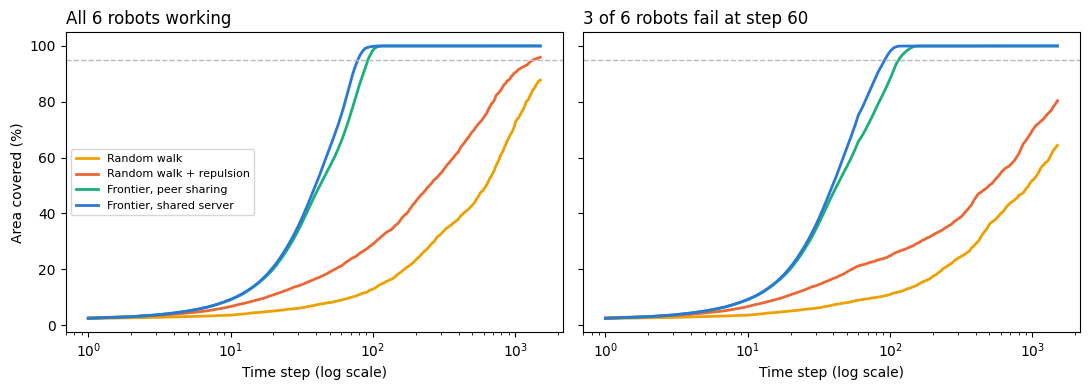

In [8]:
names = {"random": "Random walk", "repulse": "Random walk + repulsion",
         "frontier_local": "Frontier, peer sharing", "frontier_shared": "Frontier, shared server"}
colors = {"random": "#eda100", "repulse": "#eb6834",
          "frontier_local": "#1baf7a", "frontier_shared": "#2a78d6"}

# Coverage over time
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cond, title in [(axs[0], "normal", "All 6 robots working"),
                        (axs[1], "3 robots fail at step 60", "3 of 6 robots fail at step 60")]:
    for m in names:
        y = np.array(results[f"{m}|{cond}"]["curve"]) * 100
        ax.plot(np.arange(1, len(y) + 1), y, color=colors[m], lw=2, label=names[m])
    ax.set_xscale("log"); ax.axhline(95, color="#bbb", ls="--", lw=1)
    ax.set_title(title, loc="left"); ax.set_xlabel("Time step (log scale)")
axs[0].set_ylabel("Area covered (%)"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("coverage.png", dpi=200); plt.show()

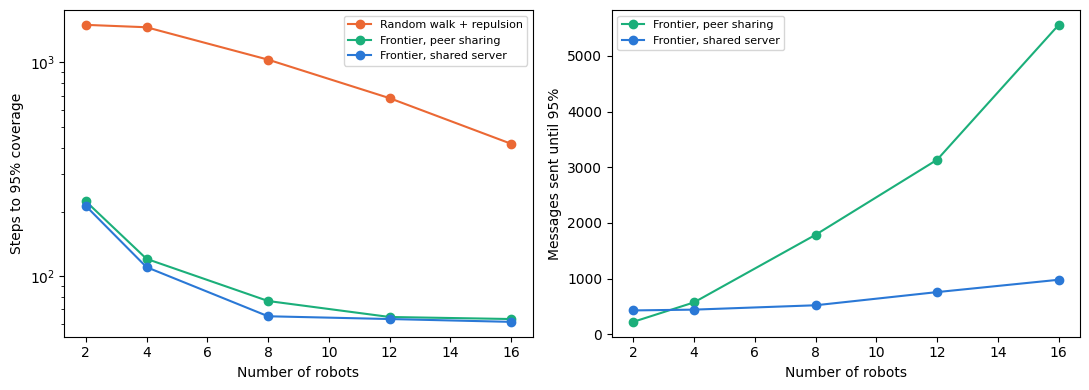

In [9]:
# Scaling with team size
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for m in ["repulse", "frontier_local", "frontier_shared"]:
    axs[0].plot(sizes, [scaling[f"{m}|{n}"]["mean"] for n in sizes], "-o", color=colors[m], label=names[m])
    if m != "repulse":
        axs[1].plot(sizes, [scaling[f"{m}|{n}"]["msgs"] for n in sizes], "-o", color=colors[m], label=names[m])
axs[0].set_yscale("log"); axs[0].set_ylabel("Steps to 95% coverage")
axs[1].set_ylabel("Messages sent until 95%")
for ax in axs:
    ax.set_xlabel("Number of robots"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("scaling.png", dpi=200); plt.show()